# Chapter 77: Political Competition, Coalitions, and Redistribution

This notebook reruns four worked examples from the chapter: inflation surprises from an uncertain election, a pre-election stimulus and its hangover, coalition size and public goods, and a ruler who blocks a productive reform. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def partisan_surprise(q, pi_l, pi_r, alpha):
    """Rational partisan surprise: pi^e = q pi_L + (1 - q) pi_R, gaps alpha(pi_i - pi^e) and E[gap^2].

    Principle: partisan-business-cycle. Book (ch077): 0.65(5.5) + 0.35(1.5) = 4.1; 0.4(1.4) = 0.56;
    0.4(-2.6) = -1.04; (0.4)^2(0.65)(0.35)(4)^2 = 0.5824.
    """
    pi_e = q * pi_l + (1 - q) * pi_r
    gl, gr = alpha * (pi_l - pi_e), alpha * (pi_r - pi_e)
    return {"pi_e": pi_e, "gap_l": gl, "gap_r": gr, "mean": q * gl + (1 - q) * gr,
            "sq": alpha ** 2 * q * (1 - q) * (pi_l - pi_r) ** 2}


def adaptive_expectations_path(pi_path, pi_e0, rho, un, beta):
    """Adaptive expectations pi^e_{t+1} = pi^e_t + rho(pi_t - pi^e_t) and u_t = u^n - beta(pi_t - pi^e_t).

    Principle: political-business-cycle. Book (ch077): pi = (2.5, 6, 2.5, 2.5), pi^e_1 2.5, rho 0.4,
    u^n 6.5, beta 0.35: u_2 5.275, pi^e_3 3.9, u_3 6.99, pi^e_4 3.34, u_4 6.794.
    """
    pe, exp_path, u_path = pi_e0, [], []
    for pi in pi_path:
        exp_path.append(pe)
        u_path.append(un - beta * (pi - pe))
        pe = pe + rho * (pi - pe)
    return {"pi": list(pi_path), "pi_e": exp_path, "u": u_path}


def selectorate_rewards(R, k, g, W, S, shift=0.0, benefit=0.0):
    """Private reward per insider b = (R - k - g) / W, loyalty ratio W / S, and a shift's net per member.

    Principle: selectorate-winning-coalition-principle. Book (ch077): R 1,200, k 240, g 160, S 1,000:
    W = 20 gives b 40 and ratio 0.02; W = 600 gives 1.33 and 0.60. Moving 300 to a service worth 0.7
    per resident costs each member 300/20 = 15 (reject) or 300/600 = 0.5 (net +0.2, accept).
    """
    pool = R - k - g
    loss = shift / W
    net = benefit - loss
    return {"pool": pool, "b": pool / W, "loyalty": W / S, "loss": loss, "gain": benefit if shift else 0.0,
            "net": net if shift else 0.0, "accept": bool(shift) and net > 0, "tie": bool(shift) and net == 0,
            "W_break": shift / benefit if benefit else math.inf, "social_gross": S * benefit}


def ruler_payoff(revenue, cost, q, V):
    """Ruler's payoff revenue - cost + (1 - q) V.

    Principle: political-replacement-effect. Book (ch077): 270 + (1 - 0.08)700 = 914;
    340 - 30 + (1 - 0.28)700 = 814; with q 0.12, 926; with cost 20 and q 0.28, 824.
    """
    return revenue - cost + (1 - q) * V


plt.rcParams.update(HOUSE_RC)


macro = SimpleNamespace(partisan_surprise=partisan_surprise, adaptive_expectations_path=adaptive_expectations_path)


public = SimpleNamespace(selectorate_rewards=selectorate_rewards, ruler_payoff=ruler_payoff)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'partisan-business-cycle': {'pi_L': 5.5,
                             'pi_R': 1.5,
                             'q': 0.65,
                             'alpha': 0.4,
                             'pi_e': 4.1,
                             'gap_L': 0.56,
                             'gap_R': -1.04,
                             'mean': 0,
                             'sq': 0.5824},
 'political-business-cycle': {'pi_normal': 2.5,
                              'un': 6.5,
                              'beta': 0.35,
                              'rho': 0.4,
                              'pi_2': 6,
                              'u_2': 5.275,
                              'pi_e3': 3.9,
                              'u_3': 6.99,
                              'pi_e4': 3.34,
                              'u_4': 6.794},
 'selectorate-winning-coalition-principle': {'R': 1200,
                                             'k': 240,
                                             'g': 160,
                                             'S': 1000,
                                             'W_A': 20,
                                             'W_B': 600,
                                             'b_A': 40,
                                             'loyalty_A': 0.02,
                                             'b_B': 1.33,
                                             'loyalty_B': 0.6,
                                             'shift': 300,
                                             'benefit': 0.7,
                                             'loss_A': 15,
                                             'loss_B': 0.5,
                                             'net_B': 0.2,
                                             'social_gross': 700},
 'political-replacement-effect': {'rev0': 270,
                                  'rev1': 340,
                                  'cost': 30,
                                  'cost_loan': 20,
                                  'V': 700,
                                  'q0': 0.08,
                                  'q1': 0.28,
                                  'q_charter': 0.12,
                                  'status_quo': 914,
                                  'reform': 814,
                                  'fiscal': 40,
                                  'replacement': 140,
                                  'charter': 926,
                                  'loan': 824},
 'constructed': {'partisan-business-cycle': {'q': [0.35, 0.5, 0.8], 'gap': [2, 6]},
                 'political-business-cycle': {'pi_2': [4, 8], 'rho': [0.2, 0.7]},
                 'selectorate-winning-coalition-principle': {'W': [100, 430]},
                 'political-replacement-effect': {'q1': [0.2]}}}


def trim(x, digits=5):
    """Up to `digits` decimals with trailing zeros removed: 5.275, 6.99, 3.34."""
    text = num(x, digits)
    return text.rstrip("0").rstrip(".") if "." in text else text


def partisan_picture(q=0.65, gap=4):
    b = BV["partisan-business-cycle"]
    pi_r, alpha = b["pi_R"], b["alpha"]
    pi_l = pi_r + gap
    res = macro.partisan_surprise(q, pi_l, pi_r, alpha)
    gl, gr = res["gap_l"], res["gap_r"]
    fig, ax = new_figure()
    ax.bar([0, 1], [gl, gr], width=0.55, color=[PALETTE["terracotta"], PALETTE["navy"]])
    label(ax, 0, gl, num(gl), col="ink", dx=0, dy=3, ha="center", va="bottom")
    label(ax, 1, gr, num(gr), col="ink", dx=0, dy=-3, ha="center", va="top")
    hline(ax, 0, "probability-weighted mean gap 0", col="grey", style="solid", x_frac=0.55, lw=1.2)
    ax.text(0.98, 0.97, f"expected inflation {num(res['pi_e'])}", transform=ax.transAxes, ha="right", va="top",
            fontsize=10.5, color=PALETTE["gold"])
    ax.set_xticks([0, 1], [f"L wins ({num(pi_l)}%), prob. {num(q)}", f"R wins ({num(pi_r)}%), prob. {num(1 - q)}"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(-2.8, 2.2)
    ax.set_xlabel("Election outcome")
    ax.set_ylabel("Output gap y - y^n (percent)")
    metrics = {"Expected inflation": num(res["pi_e"]), "Gap if L wins": num(gl), "Gap if R wins": num(gr),
               "Mean gap": num(res["mean"]), "Expected squared gap": num(res["sq"], 4)}
    steps = [f"pi^e = {num(q)} x {num(pi_l, 1)} + {num(1 - q)} x 1.5 = {num(q * pi_l, 3)} + "
             f"{num((1 - q) * 1.5, 3)} = {num(res['pi_e'])}",
             f"Gap if L = 0.4 x ({num(pi_l, 1)} - {num(res['pi_e'])}) = 0.4 x {signed(pi_l - res['pi_e'])} = {num(gl)}",
             f"Gap if R = 0.4 x (1.5 - {num(res['pi_e'])}) = 0.4 x {signed(pi_r - res['pi_e'])} = {num(gr)}",
             f"Expected squared gap = 0.16 x {num(q)} x {num(1 - q)} x {gap}^2 = {num(res['sq'], 4)}"]
    if abs(q - 0.5) < 1e-9:
        who = ("With the parties equally likely, both outcomes move output by the same amount, "
               f"{num(abs(gl))} points, in opposite directions.")
    else:
        fav, und = ("L", "R") if q > 0.5 else ("R", "L")
        who = (f"Party {fav} is the favorite, so its victory is mostly anticipated; the underdog {und} produces the "
               f"larger movement, {num(max(abs(gl), abs(gr)))} points against {num(min(abs(gl), abs(gr)))}.")
    interp = (f"Contracts build in pi^e = {num(q)} x {num(pi_l, 1)} + {num(1 - q)} x 1.5 = {num(res['pi_e'])}. "
              f"If L wins the gap is 0.4 x ({num(pi_l, 1)} - {num(res['pi_e'])}) = {num(gl)}; if R wins it is "
              f"{num(gr)}. {who} The mean gap is zero, but the expected squared gap is {num(res['sq'], 4)}.")
    alt = (f"Two bars: an output gap of {num(gl)} if L wins and {num(gr)} if R wins, around a mean of zero, with "
           f"expected inflation {num(res['pi_e'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def cycle_picture(pi2=6.0, rho=0.4):
    b = BV["political-business-cycle"]
    base, un, beta = b["pi_normal"], b["un"], b["beta"]
    path = [base, pi2, base, base]
    res = macro.adaptive_expectations_path(path, base, rho, un, beta)
    u, pe = res["u"], res["pi_e"]
    periods = [1, 2, 3, 4]
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.plot(periods, u, color=PALETTE["navy"], linewidth=2.2, marker="o")
    for t, v in zip(periods, u):
        label(ax1, t, v, trim(v), col="navy", dx=0, dy=8 if v >= un else -8, ha="center",
              va="bottom" if v >= un else "top")
    hline(ax1, un, "natural rate 6.5", col="grey", x_frac=0.70, va="top")
    vline(ax1, 2.5, "election", col="terracotta", y_frac=0.98)
    ax1.set_xticks(periods)
    ax1.set_xlim(0.6, 4.4)
    ax1.set_ylim(3.0, 9.5)
    ax1.set_xlabel("Period")
    ax1.set_ylabel("Unemployment (percent)")
    ax2.plot(periods, path, color=PALETTE["terracotta"], linewidth=2.2, marker="o", label="actual inflation")
    ax2.plot(periods, pe, color=PALETTE["gold"], linewidth=2.2, marker="s", linestyle="dashed",
             label="expected inflation")
    vline(ax2, 2.5, None, col="terracotta")
    ax2.legend(loc="upper right", frameon=False)
    ax2.set_xticks(periods)
    ax2.set_xlim(0.6, 4.4)
    ax2.set_ylim(0, 11)
    ax2.set_xlabel("Period")
    ax2.set_ylabel("Inflation (percent)")
    metrics = {"u_2": trim(u[1]), "pi_3^e": trim(pe[2]), "u_3": trim(u[2]), "pi_4^e": trim(pe[3]),
               "u_4": trim(u[3])}
    d2 = pi2 - base
    steps = [f"u_2 = 6.5 - 0.35 x ({trim(pi2)} - 2.5) = 6.5 - {trim(beta * d2)} = {trim(u[1])}",
             f"pi_3^e = 2.5 + {num(rho, 1)} x ({trim(pi2)} - 2.5) = {trim(pe[2])}",
             f"u_3 = 6.5 - 0.35 x (2.5 - {trim(pe[2])}) = 6.5 + {trim(beta * (pe[2] - base))} = {trim(u[2])}",
             f"pi_4^e = {trim(pe[2])} + {num(rho, 1)} x (2.5 - {trim(pe[2])}) = {trim(pe[3])}",
             f"u_4 = 6.5 - 0.35 x (2.5 - {trim(pe[3])}) = 6.5 + {trim(beta * (pe[3] - base))} = {trim(u[3])}"]
    if d2 == 0:
        interp = ("Without stimulus, inflation stays at 2.5 and expectations stay at 2.5, so unemployment is "
                  "6.5 - 0.35 x (2.5 - 2.5) = 6.5 in every period: no electoral cycle.")
    else:
        interp = (f"Raising election-period inflation to {trim(pi2)} surprises contracts by {trim(d2)} points, so "
                  f"u_2 = 6.5 - 0.35 x {trim(d2)} = {trim(u[1])}, a fall of {trim(un - u[1])} points before the "
                  f"vote. Expectations then catch up to {trim(pe[2])}, and with inflation back at 2.5 unemployment "
                  f"rises to {trim(u[2])}, {trim(u[2] - un)} points above natural, then {trim(u[3])} in period 4 as "
                  f"expectations close {num(rho, 1)} of each error.")
    alt = (f"Left: unemployment over four periods, {trim(u[0])}, {trim(u[1])}, {trim(u[2])} and {trim(u[3])}, with "
           f"the election after period 2. Right: actual inflation and expected inflation over the same periods.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def coalition_picture(w=20, shift=0):
    b = BV["selectorate-winning-coalition-principle"]
    res = public.selectorate_rewards(b["R"], b["k"], b["g"], w, b["S"], shift, b["benefit"])
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.bar([0], [res["b"]], width=0.5, color=PALETTE["navy"])
    label(ax1, 0, res["b"], num(res["b"]), col="ink", dx=0, dy=3, ha="center")
    ax1.set_xticks([0], [f"W = {w}"])
    ax1.set_xlim(-0.8, 0.8)
    ax1.set_ylim(0, 48)
    ax1.set_xlabel("Winning coalition size")
    ax1.set_ylabel("Private reward per insider")
    if shift:
        vals = [res["loss"], res["gain"]]
        ax2.bar([0, 1], vals, width=0.55, color=[PALETTE["terracotta"], PALETTE["teal"]])
        for x_, v in zip([0, 1], vals):
            label(ax2, x_, v, num(v, 4), col="ink", dx=0, dy=3, ha="center")
        ax2.set_ylim(0, max(vals) * 1.3)
        ax2.set_title("Accepted by insiders" if res["accept"] else "Rejected by insiders", fontsize=12)
    else:
        ax2.bar([0, 1], [0, 0], width=0.55)
        ax2.text(0.5, 0.5, "no shift proposed", transform=ax2.transAxes, ha="center", va="center", fontsize=12,
                 color=PALETTE["grey"])
        ax2.set_ylim(0, 1)
    ax2.set_xticks([0, 1], ["lost reward per member", "service benefit"])
    ax2.set_xlabel(f"Shift of {shift} units to universal service")
    ax2.set_ylabel("Per coalition member")
    if not shift:
        verdict = "no shift proposed"
    else:
        verdict = "accept" if res["accept"] else ("tie" if res["tie"] else "reject")
    metrics = {"Private reward per insider": num(res["b"]), "Loyalty ratio W / S": num(res["loyalty"], 3),
               "Loss per member from shift": num(res["loss"], 4), "Gain per member": num(res["gain"], 4),
               "Net per member": num(res["net"], 4), "Verdict": verdict}
    steps = [f"b = (1,200 - 240 - 160) / {w} = 800 / {w} = {num(res['b'])}",
             f"Loyalty ratio = {w} / 1,000 = {num(res['loyalty'], 3)}"]
    if shift:
        steps += [f"Loss per member = {shift} / {w} = {num(res['loss'], 4)}",
                  f"Net = 0.7 - {num(res['loss'], 4)} = {num(res['net'], 4)}",
                  f"Acceptance needs {shift} / W < 0.7, i.e. W > {num(res['W_break'], 1)}"]
        tail = (f"Moving {shift} units to a service worth 0.7 per resident costs each member {shift} / {w} = "
                f"{num(res['loss'], 4)} of private reward, so the net is 0.7 - {num(res['loss'], 4)} = "
                f"{num(res['net'], 4)} and the coalition {'accepts' if res['accept'] else 'rejects'} the shift. "
                f"Any coalition larger than {num(res['W_break'], 1)} would accept it.")
    else:
        tail = "No shift is proposed, so insiders keep the full private reward."
    interp = (f"With {w} essential supporters, each insider receives (1,200 - 240 - 160) / {w} = 800 / {w} = "
              f"{num(res['b'])}, and the loyalty ratio is {w} / 1,000 = {num(res['loyalty'], 3)}. {tail}")
    alt = (f"Left: a private reward of {num(res['b'])} per insider with a coalition of {w}. Right: "
           + (f"the loss per member {num(res['loss'], 4)} against the 0.7 service benefit."
              if shift else "no shift proposed."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ruler_picture(q1=0.28, c=30):
    b = BV["political-replacement-effect"]
    V, q0 = b["V"], b["q0"]
    sq = public.ruler_payoff(b["rev0"], 0, q0, V)
    rf = public.ruler_payoff(b["rev1"], c, q1, V)
    fiscal = b["rev1"] - b["rev0"] - c
    repl = (q1 - q0) * V
    cont0, cont1 = (1 - q0) * V, (1 - q1) * V
    reform = rf > sq
    fig, ax = new_figure()
    stacked_bar(ax, ["status quo", "reform"], [[b["rev0"], b["rev1"] - c], [cont0, cont1]],
                ["current revenue net of cost", "expected value of another term"], colors=["gold", "teal"],
                ylabel="Ruler's payoff", fmt=lambda v: num(v, 0))
    ax.legend(loc="upper right", frameon=False)
    ax.set_ylim(0, 1250)
    ax.set_xlabel("Ruler's option")
    metrics = {"Status quo payoff": num(sq, 0), "Reform payoff": num(rf, 0), "Net fiscal gain": num(fiscal, 0),
               "Replacement cost": num(repl, 0), "Decision": "reform" if reform else "block"}
    steps = ["Status quo: 270 + (1 - 0.08) x 700 = 270 + 644 = 914",
             f"Reform: 340 - {c} + (1 - {num(q1)}) x 700 = {340 - c} + {num(cont1, 0)} = {num(rf, 0)}",
             f"Net fiscal gain = 340 - 270 - {c} = {num(fiscal, 0)}",
             f"Replacement cost = ({num(q1)} - 0.08) x 700 = {num(repl, 0)}",
             f"{num(fiscal, 0)} - {num(repl, 0)} = {num(rf - sq, 0)}: {'reform' if reform else 'block'}"]
    interp = (f"Reform pays 340 - {c} + (1 - {num(q1)}) x 700 = {num(rf, 0)} against 914 under the status quo. "
              + (f"It adds {num(fiscal, 0)} of revenue net of implementation and the higher replacement risk costs "
                 f"only {num(repl, 0)} of expected tenure, so the ruler adopts it." if reform else
                 f"It adds {num(fiscal, 0)} of revenue net of implementation but the higher replacement risk costs "
                 f"{num(repl, 0)} of expected tenure, so the ruler blocks it, whatever happens to national output."))
    alt = (f"Stacked bars: status quo 914 (270 revenue plus 644 expected tenure value) against reform "
           f"{num(rf, 0)} ({340 - c} net revenue plus {num(cont1, 0)}).")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Partisan business cycle: election uncertainty

Party L would run 5.5 percent inflation and R 1.5 percent; L wins with probability 0.65 and the output response is 0.4 per point of surprise.

$$\pi^e=0.65(5.5)+0.35(1.5)=4.1, \qquad y_R-y^n=0.4(1.5-4.1)=-1.04$$

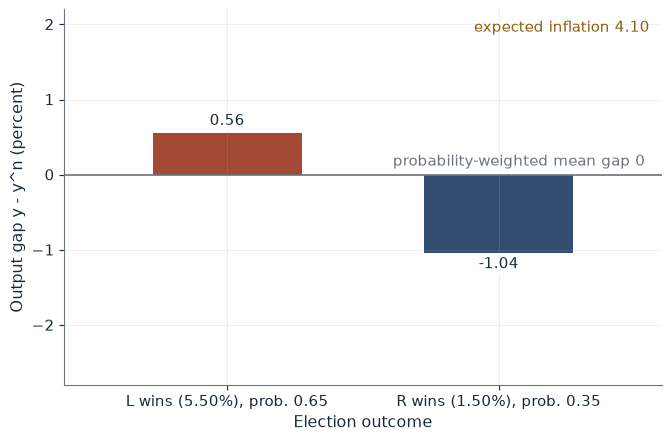

Expected inflation    4.10
Gap if L wins         0.56
Gap if R wins         -1.04
Mean gap              0.00
Expected squared gap  0.5824

Worked steps:
  1. pi^e = 0.65 x 5.5 + 0.35 x 1.5 = 3.575 + 0.525 = 4.10
  2. Gap if L = 0.4 x (5.5 - 4.10) = 0.4 x 1.40 = 0.56
  3. Gap if R = 0.4 x (1.5 - 4.10) = 0.4 x (-2.60) = -1.04
  4. Expected squared gap = 0.16 x 0.65 x 0.35 x 4^2 = 0.5824

Contracts build in pi^e = 0.65 x 5.5 + 0.35 x 1.5 = 4.10. If L wins the gap is 0.4 x (5.5 - 4.10) = 0.56; if R wins it is -1.04. Party L is the favorite, so its victory is mostly anticipated; the underdog R produces the larger movement, 1.04 points against 0.56. The mean gap is zero, but the expected squared gap is 0.5824.


In [2]:
show(partisan_picture(q=0.65, gap=4))

Change one input, `q`, and hold the others at the book's values:

In [3]:
sweep(partisan_picture, 'q', [0.35, 0.5, 0.65, 0.8], {'gap': 4}, ['Expected inflation', 'Gap if L wins', 'Gap if R wins', 'Expected squared gap'])

q | Expected inflation | Gap if L wins | Gap if R wins | Expected squared gap
0.35 | 2.90 | 1.04 | -0.56 | 0.5824
0.5 | 3.50 | 0.80 | -0.80 | 0.6400
0.65 | 4.10 | 0.56 | -1.04 | 0.5824
0.8 | 4.70 | 0.32 | -1.28 | 0.4096


The underdog's victory moves output more (-1.04 against 0.56) because it was less expected; the probability-weighted mean gap is zero.

## 2. Political business cycle: stimulus and hangover

Natural unemployment 6.5, slope 0.35, normal inflation 2.5, adjustment 0.4; inflation is raised to 6 in the election period.

$$u_2=6.5-0.35(6-2.5)=5.275, \qquad \pi_3^e=2.5+0.4(6-2.5)=3.9, \qquad u_3=6.5-0.35(2.5-3.9)=6.99$$

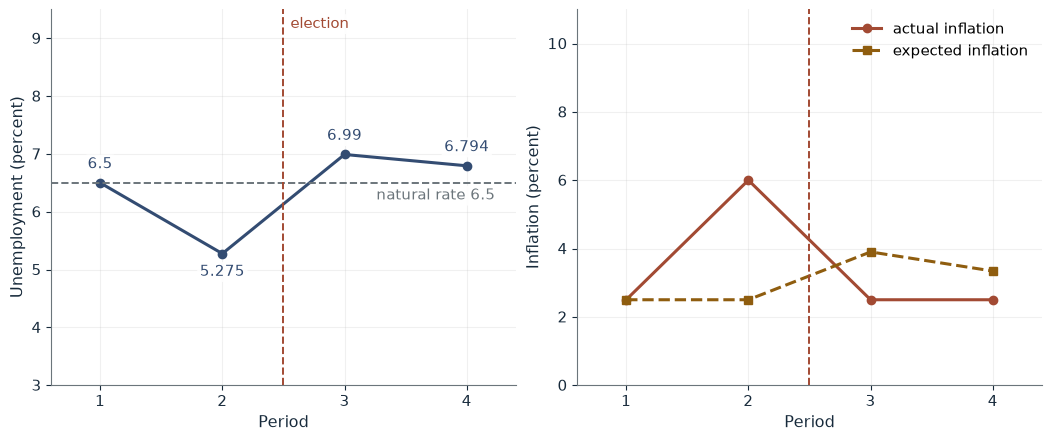

u_2     5.275
pi_3^e  3.9
u_3     6.99
pi_4^e  3.34
u_4     6.794

Worked steps:
  1. u_2 = 6.5 - 0.35 x (6 - 2.5) = 6.5 - 1.225 = 5.275
  2. pi_3^e = 2.5 + 0.4 x (6 - 2.5) = 3.9
  3. u_3 = 6.5 - 0.35 x (2.5 - 3.9) = 6.5 + 0.49 = 6.99
  4. pi_4^e = 3.9 + 0.4 x (2.5 - 3.9) = 3.34
  5. u_4 = 6.5 - 0.35 x (2.5 - 3.34) = 6.5 + 0.294 = 6.794

Raising election-period inflation to 6 surprises contracts by 3.5 points, so u_2 = 6.5 - 0.35 x 3.5 = 5.275, a fall of 1.225 points before the vote. Expectations then catch up to 3.9, and with inflation back at 2.5 unemployment rises to 6.99, 0.49 points above natural, then 6.794 in period 4 as expectations close 0.4 of each error.


In [4]:
show(cycle_picture(pi2=6.0, rho=0.4))

Change one input, `pi2`, and hold the others at the book's values:

In [5]:
sweep(cycle_picture, 'pi2', [2.5, 4.0, 6.0, 8.0], {'rho': 0.4}, ['u_2', 'u_3', 'u_4'])

pi2 | u_2 | u_3 | u_4
2.5 | 6.5 | 6.5 | 6.5
4.0 | 5.975 | 6.71 | 6.626
6.0 | 5.275 | 6.99 | 6.794
8.0 | 4.575 | 7.27 | 6.962


Unemployment falls 1.225 points before the vote and rises to 6.99 afterward. Without the surprise (`pi2=2.5`) it stays at 6.5 throughout.

## 3. Selectorate theory: coalition size and public goods

Revenue 1,200, retained 240, broad services 160, selectorate 1,000.

$$b_A=\frac{1{,}200-240-160}{20}=40, \qquad \lambda_A=\frac{20}{1{,}000}=0.02$$

Moving 300 units to a service worth 0.7 per resident costs each member $300/W$.

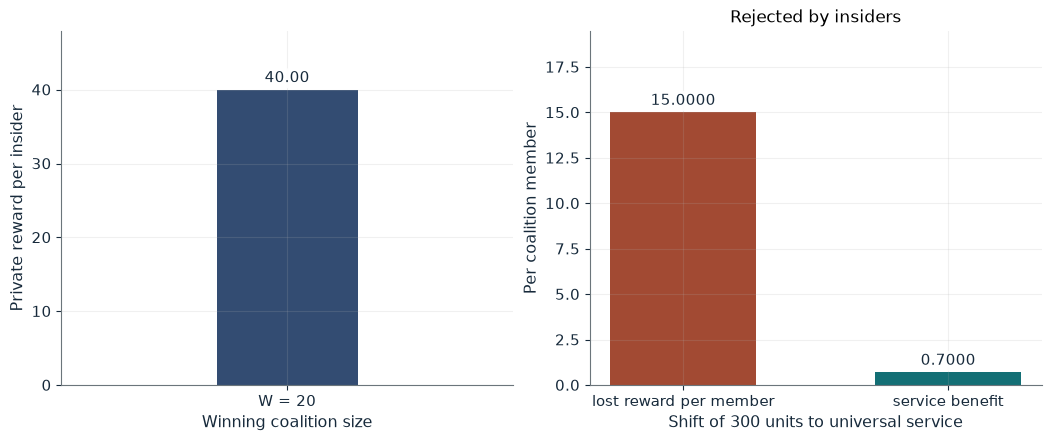

Private reward per insider  40.00
Loyalty ratio W / S         0.020
Loss per member from shift  15.0000
Gain per member             0.7000
Net per member              -14.3000
Verdict                     reject

Worked steps:
  1. b = (1,200 - 240 - 160) / 20 = 800 / 20 = 40.00
  2. Loyalty ratio = 20 / 1,000 = 0.020
  3. Loss per member = 300 / 20 = 15.0000
  4. Net = 0.7 - 15.0000 = -14.3000
  5. Acceptance needs 300 / W < 0.7, i.e. W > 428.6

With 20 essential supporters, each insider receives (1,200 - 240 - 160) / 20 = 800 / 20 = 40.00, and the loyalty ratio is 20 / 1,000 = 0.020. Moving 300 units to a service worth 0.7 per resident costs each member 300 / 20 = 15.0000 of private reward, so the net is 0.7 - 15.0000 = -14.3000 and the coalition rejects the shift. Any coalition larger than 428.6 would accept it.


In [6]:
show(coalition_picture(w=20, shift=300))

Change one input, `w`, and hold the others at the book's values:

In [7]:
sweep(coalition_picture, 'w', [20, 100, 430, 600], {'shift': 300}, ['Private reward per insider', 'Loss per member from shift', 'Net per member', 'Verdict'])

w | Private reward per insider | Loss per member from shift | Net per member | Verdict
20 | 40.00 | 15.0000 | -14.3000 | reject
100 | 8.00 | 3.0000 | -2.3000 | reject
430 | 1.86 | 0.6977 | 0.0023 | accept
600 | 1.33 | 0.5000 | 0.2000 | accept


A coalition of 20 loses 15 each and rejects; at 600 members the loss is 0.5 against a gain of 0.7. The shift becomes acceptable once W exceeds 300 / 0.7 = 428.6.

## 4. Political replacement effect

Status quo revenue 270 with replacement probability 0.08; reform revenue 340, cost 30, replacement 0.28; another term is worth 700.

$$270+(1-0.08)700=914, \qquad 340-30+(1-0.28)700=814$$

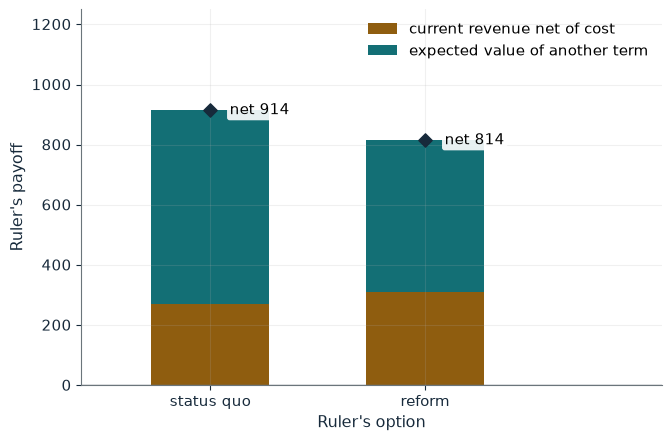

Status quo payoff  914
Reform payoff      814
Net fiscal gain    40
Replacement cost   140
Decision           block

Worked steps:
  1. Status quo: 270 + (1 - 0.08) x 700 = 270 + 644 = 914
  2. Reform: 340 - 30 + (1 - 0.28) x 700 = 310 + 504 = 814
  3. Net fiscal gain = 340 - 270 - 30 = 40
  4. Replacement cost = (0.28 - 0.08) x 700 = 140
  5. 40 - 140 = -100: block

Reform pays 340 - 30 + (1 - 0.28) x 700 = 814 against 914 under the status quo. It adds 40 of revenue net of implementation but the higher replacement risk costs 140 of expected tenure, so the ruler blocks it, whatever happens to national output.


In [8]:
show(ruler_picture(q1=0.28, c=30))

Change one input, `q1`, and hold the others at the book's values:

In [9]:
sweep(ruler_picture, 'q1', [0.12, 0.2, 0.28], {'c': 30}, ['Reform payoff', 'Replacement cost', 'Decision'])

q1 | Reform payoff | Replacement cost | Decision
0.12 | 926 | 28 | reform
0.2 | 870 | 84 | block
0.28 | 814 | 140 | block


Reform adds 40 of net revenue but costs 140 of expected tenure, so the ruler blocks it. A charter holding replacement risk to 0.12 raises the reform payoff to 926 and reform proceeds.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

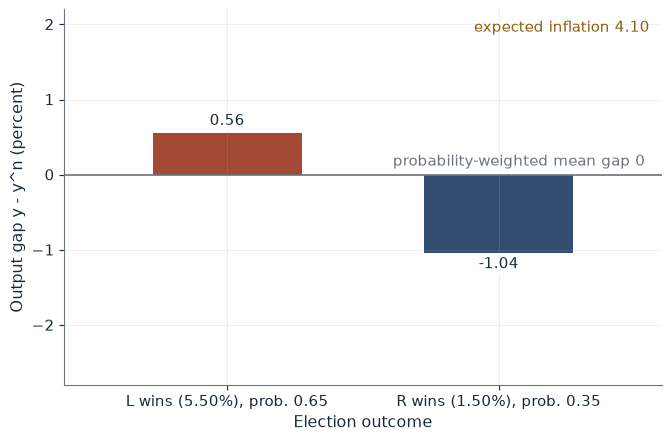

Expected inflation    4.10
Gap if L wins         0.56
Gap if R wins         -1.04
Mean gap              0.00
Expected squared gap  0.5824

Worked steps:
  1. pi^e = 0.65 x 5.5 + 0.35 x 1.5 = 3.575 + 0.525 = 4.10
  2. Gap if L = 0.4 x (5.5 - 4.10) = 0.4 x 1.40 = 0.56
  3. Gap if R = 0.4 x (1.5 - 4.10) = 0.4 x (-2.60) = -1.04
  4. Expected squared gap = 0.16 x 0.65 x 0.35 x 4^2 = 0.5824

Contracts build in pi^e = 0.65 x 5.5 + 0.35 x 1.5 = 4.10. If L wins the gap is 0.4 x (5.5 - 4.10) = 0.56; if R wins it is -1.04. Party L is the favorite, so its victory is mostly anticipated; the underdog R produces the larger movement, 1.04 points against 0.56. The mean gap is zero, but the expected squared gap is 0.5824.


In [10]:
show(partisan_picture(q=0.65, gap=4))

## Practice

**1.** If L's chance were 0.50, what is expected inflation and the output gap if R wins?

<details><summary>Answer</summary>

pi^e = 0.5 x 5.5 + 0.5 x 1.5 = 3.5; the gap is 0.4 x (1.5 - 3.5) = -0.8 (0.50 is a constructed value).

</details>

**2.** For W = 600, what is each coalition member's net from the 300-unit shift?

<details><summary>Answer</summary>

Loss 300 / 600 = 0.5, gain 0.7, net +0.2, so the coalition accepts.

</details>

**3.** Will a loan that cuts implementation cost to 20 make the ruler reform?

<details><summary>Answer</summary>

No: 340 - 20 + 0.72 x 700 = 824, below 914.

</details>